# House Prices: MLP

## 1. Loading and preparing the dataset

In [24]:
import time
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
df = pd.read_csv('house-prices-advanced-regression-techniques/train.csv', na_values=["NA"], keep_default_na=True)

TARGET = 'SalePrice'
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Exploratory data analysis

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [5]:
missing = df.drop(columns=[TARGET], errors='ignore').isna().sum()[lambda s: s > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({'n_missing': missing, 'pct_missing': missing_pct})
missing_table

,n_missing,pct_missing
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


### Feature matrix X and target vector y

In [6]:
X_raw = df.drop(columns=[TARGET, 'Id'], errors='ignore').copy()
y = df[TARGET].copy()

In [10]:
X_raw['MSSubClass'] = X_raw['MSSubClass'].astype(str)

numeric_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_raw.select_dtypes(include=[str]).columns.tolist()

print(f"Number of numeric features: {len(numeric_cols)}")
print(f"Number of categorical features: {len(categorical_cols)}")

Number of numeric features: 35
Number of categorical features: 44


## 3. Splitting into train, validation, and test sets

In [11]:
price_bins_strat = pd.qcut(y, q=5, duplicates='drop')

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_STATE, stratify=price_bins_strat)

strat_trainval = pd.qcut(y_trainval, q=5, duplicates='drop')
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE, stratify=strat_trainval)

print(f"X_train: {X_train.shape} ({len(X_train)/len(X_raw):.0%})")
print(f"X_val:   {X_val.shape} ({len(X_val)/len(X_raw):.0%})")
print(f"X_test:  {X_test.shape} ({len(X_test)/len(X_raw):.0%})")

X_train: (876, 79) (60%)
X_val:   (292, 79) (20%)
X_test:  (292, 79) (20%)


## 4. Handling missing values, encoding, and feature scaling

In [12]:
NONE_MEANS_ABSENCE = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu', 
       'GarageType', 'GarageCond', 'GarageFinish', 'GarageQual', 'BsmtFinType2', 
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1']


def build_preprocessor(X_fit_raw):
    Xf = X_fit_raw.copy()
    for col in NONE_MEANS_ABSENCE:
       Xf[col] = Xf[col].fillna('None')
    
    cat_cols = Xf.select_dtypes(include=[str]).columns.tolist()
    num_cols = Xf.select_dtypes(include=[np.number]).columns.tolist()

    remaining_cat = [c for c in cat_cols if Xf[c].isna().any()]
    remaining_num = [c for c in num_cols if Xf[c].isna().any()]

    cat_imputer = SimpleImputer(strategy='most_frequent')
    if remaining_cat:
        cat_imputer.fit(Xf[remaining_cat])
        Xf[remaining_cat] = cat_imputer.transform(Xf[remaining_cat])

    num_imputer = SimpleImputer(strategy='median')
    if remaining_num:
        num_imputer.fit(Xf[remaining_num])
        Xf[remaining_num] = num_imputer.transform(Xf[remaining_num])

    iqr_bounds = {}
    for c in num_cols:
        q1, q3 = Xf[c].quantile(0.25), Xf[c].quantile(0.75)
        iqr = q3 - q1
        iqr_bounds[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
        Xf[c] = Xf[c].clip(lower=iqr_bounds[c][0], upper=iqr_bounds[c][1])

        ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        ohe.fit(Xf[cat_cols])

        scaler = StandardScaler()
        scaler.fit(Xf[num_cols])

    return dict(cat_cols=cat_cols, num_cols=num_cols, 
                remaining_cat=remaining_cat, remaining_num=remaining_num, 
                cat_imputer=cat_imputer, num_imputer=num_imputer,
                iqr_bounds=iqr_bounds, ohe=ohe, scaler=scaler)


def apply_preprocessor(X_raw, prep):
    Xr = X_raw.copy()
    for col in NONE_MEANS_ABSENCE:
        Xr[col] = Xr[col].fillna('None')

    if prep['remaining_cat']:
        Xr[prep['remaining_cat']] = prep['cat_imputer'].transform(Xr[prep['remaining_cat']])
    if prep['remaining_num']:
        Xr[prep['remaining_num']] = prep['num_imputer'].transform(Xr[prep['remaining_num']])

    for c in prep['num_cols']:
        lo, hi = prep['iqr_bounds'][c]
        Xr[c] = Xr[c].clip(lower=lo, upper=hi)

    X_cat = pd.DataFrame(
        prep['ohe'].transform(Xr[prep['cat_cols']]),
        columns=prep['ohe'].get_feature_names_out(prep['cat_cols']),
        index=Xr.index
    )
    X_num = pd.DataFrame(
        prep['scaler'].transform(Xr[prep['num_cols']]),
        columns=prep['num_cols'],
        index=Xr.index
    )   
    return pd.concat([X_num, X_cat], axis=1)

In [17]:
prep = build_preprocessor(X_train)

X_train_final = apply_preprocessor(X_train, prep).reset_index(drop=True)
X_val_final = apply_preprocessor(X_val, prep).reset_index(drop=True)
X_test_final = apply_preprocessor(X_test, prep).reset_index(drop=True)

feature_names = X_train_final.columns.tolist()
n_features = len(feature_names)

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_val_scaled = y_scaler.transform(y_val.values.reshape(-1, 1)).ravel()
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1)).ravel()

print(f"X_train_final: {X_train_final.shape}")
print(f"X_val_final:   {X_val_final.shape}")
print(f"X_test_final:  {X_test_final.shape}")
print(f"Number of input features (input layer neurons): {n_features}")

X_train_final: (876, 304)
X_val_final:   (292, 304)
X_test_final:  (292, 304)
Number of input features (input layer neurons): 304


In [18]:
def to_tensor(X_df, y_arr=None):
    X_t = torch.tensor(X_df.values, dtype=torch.float32)
    if y_arr is None:
        return X_t
    y_t = torch.tensor(y_arr, dtype=torch.float32).view(-1, 1)
    return X_t, y_t

X_train_t, y_train_t = to_tensor(X_train_final, y_train_scaled)
X_val_t, y_val_t = to_tensor(X_val_final, y_val_scaled)
X_test_t, y_test_t = to_tensor(X_test_final, y_test_scaled)

BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, 
                          generator=torch.Generator().manual_seed(RANDOM_STATE))

print(f"X_train_t: {X_train_t.shape}, y_train_t: {y_train_t.shape}")

X_train_t: torch.Size([876, 304]), y_train_t: torch.Size([876, 1])


## 5. Base MLP architecture

In [22]:
class MLPRegressor(nn.Module):
    def __init__(self, input_dim, hidden_sizes=(128, 64), dropout_p=0.0, activation=nn.ReLU):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(activation())
            if dropout_p > 0:
                layers.append(nn.Dropout(dropout_p))
            prev_dim = h
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
            
model_demo = MLPRegressor(input_dim=n_features, hidden_sizes=(128, 64))
print(model_demo)
print(f"\nNumber of trainable parameters: {count_parameters(model_demo):,}")

MLPRegressor(
  (net): Sequential(
    (0): Linear(in_features=304, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Number of trainable parameters: 47,361


## 6. Loss function, optimizer, and training hyperparameters

In [ ]:
LEARNING_RATE = 0.001
N_EPOCHS_BASE = 150

print(f"Loss function: MSELoss")
print(f"Optimizer: Adam")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs (base model): {N_EPOCHS_BASE}")

Loss function: MSELoss
Optimizer: Adam
Learning rate: 0.001
Batch size: 32
Epochs (base model): 150


## 7–8. Training the base MLP model (without regularization)

In [25]:
def train_model(model, train_loader, X_val_t, y_val_t, n_epochs, learning_rate=0.001,
                 weight_decay=0.0, early_stopping_patience=None, verbose=False):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    history = {'train_loss': [], 'val_loss': []}
    best_val_loss = float('inf')
    best_state = None
    epochs_no_improve = 0
    stopped_epoch = n_epochs

    t0 = time.time()
    for epoch in range(n_epochs):
        model.train()
        running_loss = 0.0
        n_batches = 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            n_batches += 1
        train_loss = running_loss / n_batches

        model.eval()
        with torch.no_grad():
            val_pred = model(X_val_t)
            val_loss = criterion(val_pred, y_val_t).item()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose and (epoch % 20 == 0 or epoch == n_epochs - 1):
            print(f"  Epoch {epoch+1}/{n_epochs}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")
    
        if early_stopping_patience is not None and epochs_no_improve >= early_stopping_patience:
            stopped_epoch = epoch + 1
            if verbose:
                print(f"  Early stopping at epoch {stopped_epoch} (val_loss did not improve for {early_stopping_patience} consecutive epochs)")
            break

    train_time = time.time() - t0
    
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, {'train_time': train_time, 'best_val_loss': best_val_loss, 'n_epochs_trained': stopped_epoch}

In [26]:
torch.manual_seed(RANDOM_STATE)
model_base = MLPRegressor(input_dim=n_features, hidden_sizes=(128, 64), dropout_p=0.0)

print("Training the base MLP model (without regularization)...")
model_base, history_base, info_base = train_model(
    model_base, train_loader, X_val_t, y_val_t,
    n_epochs=N_EPOCHS_BASE, learning_rate=LEARNING_RATE, weight_decay=0.0,
    early_stopping_patience=None, verbose=True
)

print(f"\nTraining time: {info_base['train_time']:.2f} s")
print(f"Best val_loss (MSE, scaled space): {info_base['best_val_loss']:.4f}")
print(f"Number of model parameters: {count_parameters(model_base):,}")

Training the base MLP model (without regularization)...
  Epoch 1/150: train_loss=0.4477, val_loss=0.1144
  Epoch 21/150: train_loss=0.0089, val_loss=0.0851
  Epoch 41/150: train_loss=0.0030, val_loss=0.0865
  Epoch 61/150: train_loss=0.0017, val_loss=0.0835
  Epoch 81/150: train_loss=0.0019, val_loss=0.0808
  Epoch 101/150: train_loss=0.0021, val_loss=0.0864
  Epoch 121/150: train_loss=0.0021, val_loss=0.0828
  Epoch 141/150: train_loss=0.0023, val_loss=0.0746
  Epoch 150/150: train_loss=0.0019, val_loss=0.0806

Training time: 9.92 s
Best val_loss (MSE, scaled space): 0.0642
Number of model parameters: 47,361


## 9. Plots of the base model training process

In [27]:
def regression_metrics(y_true_scaled, y_pred_scaled, scaler):
    y_true = scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).ravel()
    y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}


def predict_np(model, X_t):
    model.eval()
    with torch.no_grad():
        pred = model(X_t).cpu().numpy().ravel()
    return pred


def evaluate_model(model, X_t, y_scaled_arr, scaler):
    pred_scaled = predict_np(model, X_t)
    return regression_metrics(y_scaled_arr, pred_scaled, scaler)


base_train_metrics = evaluate_model(model_base, X_train_t, y_train_scaled, y_scaler)
base_val_metrics = evaluate_model(model_base, X_val_t, y_val_scaled, y_scaler)

print("Base MLP model metrics:")
pd.DataFrame({'train': base_train_metrics, 'validation': base_val_metrics}).T

Base MLP model metrics:


,MAE,MSE,RMSE,R2
train,11405.887869,3.829304e+08,19568.606652,0.944861
validation,14273.109161,4.457703e+08,21113.271940,0.927922


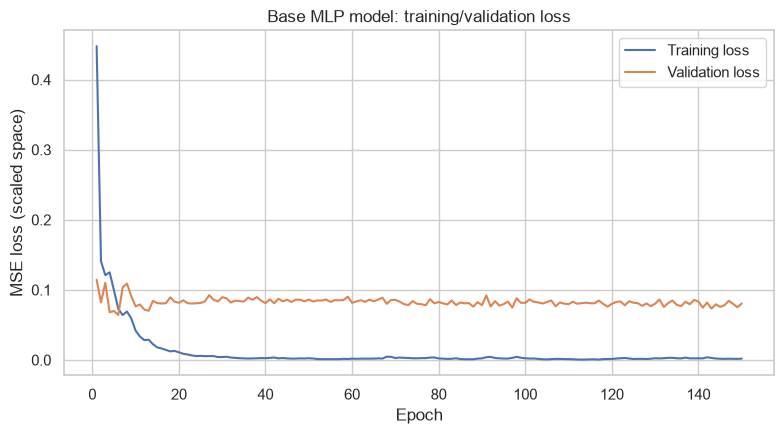

In [28]:
def plot_training_history(history, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4.5))
    epochs_range = range(1, len(history['train_loss']) + 1)
    ax.plot(epochs_range, history['train_loss'], label='Training loss')
    ax.plot(epochs_range, history['val_loss'], label='Validation loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE loss (scaled space)')
    ax.set_title(title)
    ax.legend()
    return ax


plot_training_history(history_base, 'Base MLP model: training/validation loss')
plt.tight_layout()
plt.show()

## 10. Analysis of the training process

In [29]:
min_train_loss = min(history_base['train_loss'])
min_val_loss = min(history_base['val_loss'])
final_train_loss = history_base['train_loss'][-1]
final_val_loss = history_base['val_loss'][-1]
best_val_epoch = int(np.argmin(history_base['val_loss'])) + 1

print(f"Minimum training loss: {min_train_loss:.4f} (at the last epoch: {final_train_loss:.4f})")
print(f"Minimum validation loss: {min_val_loss:.4f} (reached at epoch {best_val_epoch} of {N_EPOCHS_BASE})")
print(f"Validation loss at the last epoch: {final_val_loss:.4f}")
print(f"\nR2 train: {base_train_metrics['R2']:.4f}, R2 validation: {base_val_metrics['R2']:.4f}")
print(f"R2 gap (train - val): {base_train_metrics['R2'] - base_val_metrics['R2']:.4f}")

Minimum training loss: 0.0005 (at the last epoch: 0.0019)
Minimum validation loss: 0.0642 (reached at epoch 6 of 150)
Validation loss at the last epoch: 0.0806

R2 train: 0.9449, R2 validation: 0.9279
R2 gap (train - val): 0.0169


## 11. Effect of network architecture

In [ ]:
architectures = {
    'Small (1 layer, 32)':          {'hidden_sizes': (32,),        'activation': nn.ReLU},
    'Base (2 layers, 128-64)':      {'hidden_sizes': (128, 64),    'activation': nn.ReLU},
    'Deeper (3 layers, 128-64-32)': {'hidden_sizes': (128, 64, 32), 'activation': nn.ReLU},
    'Wide (2 layers, 256-128)':     {'hidden_sizes': (256, 128),   'activation': nn.ReLU},
    'Base, Tanh':                   {'hidden_sizes': (128, 64),    'activation': nn.Tanh},
}

architecture_results = []
architecture_models = {}
architecture_histories = {}

for name, cfg in architectures.items():
    torch.manual_seed(RANDOM_STATE)
    model = MLPRegressor(input_dim=n_features, hidden_sizes=cfg['hidden_sizes'],
                          dropout_p=0.0, activation=cfg['activation'])
    model, history, info = train_model(model, train_loader, X_val_t, y_val_t,
                                        n_epochs=N_EPOCHS_BASE, learning_rate=LEARNING_RATE,
                                        weight_decay=0.0, early_stopping_patience=None, verbose=False)
    val_metrics = evaluate_model(model, X_val_t, y_val_scaled, y_scaler)
    train_metrics = evaluate_model(model, X_train_t, y_train_scaled, y_scaler)

    architecture_models[name] = model
    architecture_histories[name] = history
    architecture_results.append({
        'architecture': name, 'n_params': count_parameters(model),
        'train_time_s': round(info['train_time'], 2),
        'best_val_loss': round(info['best_val_loss'], 4),
        'R2_train': round(train_metrics['R2'], 4), 'R2_val': round(val_metrics['R2'], 4),
        'RMSE_val': round(val_metrics['RMSE'], 1),
    })
    print(f"'{name}': done (n_params={count_parameters(model):,}, "
          f"val_loss={info['best_val_loss']:.4f}, time={info['train_time']:.1f}s)")

architecture_results_df = pd.DataFrame(architecture_results)
architecture_results_df

'Small (1 layer, 32)': done (n_params=9,793, val_loss=0.0732, time=5.8s)
'Base (2 layers, 128-64)': done (n_params=47,361, val_loss=0.0675, time=9.1s)
'Deeper (3 layers, 128-64-32)': done (n_params=49,409, val_loss=0.0686, time=9.5s)
'Wide (2 layers, 256-128)': done (n_params=111,105, val_loss=0.0690, time=12.7s)
'Base, Tanh': done (n_params=47,361, val_loss=0.0763, time=8.4s)


,architecture,n_params,train_time_s,best_val_loss,R2_train,R2_val,RMSE_val
0,"Small (1 layer, 32)",9793,5.78,0.0732,0.9339,0.9177,22554.5
1,"Base (2 layers, 128-64)",47361,9.14,0.0675,0.9269,0.9242,21652.5
2,"Deeper (3 layers, 128-64-32)",49409,9.54,0.0686,0.9170,0.9230,21825.3
3,"Wide (2 layers, 256-128)",111105,12.68,0.0690,0.9959,0.9225,21886.4
4,"Base, Tanh",47361,8.39,0.0763,0.9204,0.9143,23022.9


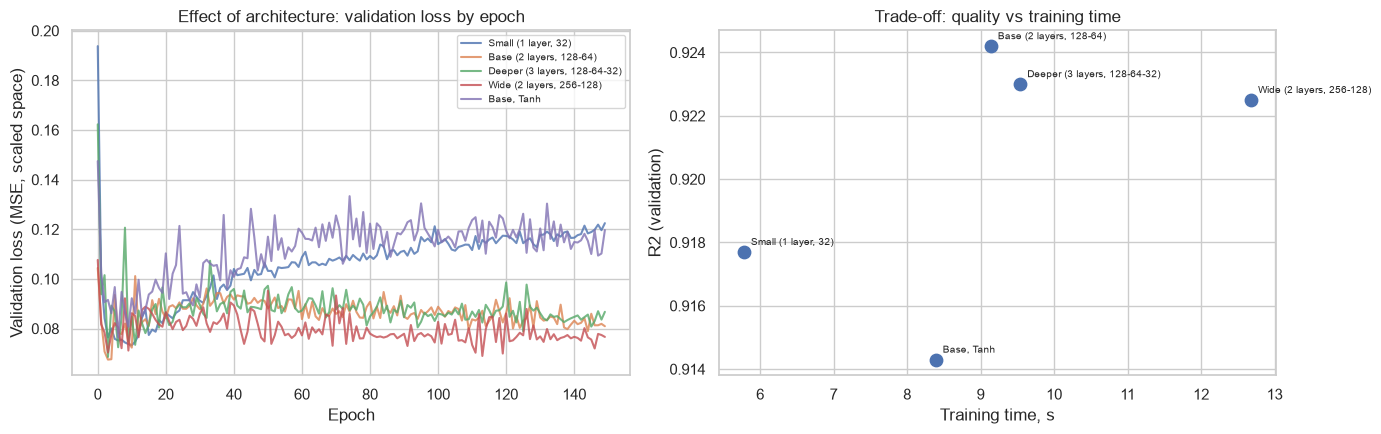

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for name, history in architecture_histories.items():
    axes[0].plot(history['val_loss'], label=name, alpha=0.8)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation loss (MSE, scaled space)')
axes[0].set_title('Effect of architecture: validation loss by epoch')
axes[0].legend(fontsize=7)

axes[1].scatter(architecture_results_df['train_time_s'], architecture_results_df['R2_val'], s=80)
for _, row in architecture_results_df.iterrows():
    axes[1].annotate(row['architecture'], (row['train_time_s'], row['R2_val']), fontsize=7,
                      xytext=(5, 5), textcoords='offset points')
axes[1].set_xlabel('Training time, s')
axes[1].set_ylabel('R2 (validation)')
axes[1].set_title('Trade-off: quality vs training time')

plt.tight_layout()
plt.show()

## 12–13. Regularization methods and comparison with the base model

In [33]:
regularization_configs = {
    'Dropout (p=0.3)':        {'dropout_p': 0.3, 'weight_decay': 0.0,  'early_stopping_patience': None},
    'L2 (weight_decay=1e-3)': {'dropout_p': 0.0, 'weight_decay': 1e-3, 'early_stopping_patience': None},
    'Early Stopping (patience=15)': {'dropout_p': 0.0, 'weight_decay': 0.0, 'early_stopping_patience': 15},
    'Combined (Dropout+L2+ES)':     {'dropout_p': 0.3, 'weight_decay': 1e-3, 'early_stopping_patience': 15},
}

reg_results = []
reg_models = {}
reg_histories = {}
reg_infos = {}

for name, cfg in regularization_configs.items():
    torch.manual_seed(RANDOM_STATE)
    model = MLPRegressor(input_dim=n_features, hidden_sizes=(128, 64), dropout_p=cfg['dropout_p'])
    model, history, info = train_model(
        model, train_loader, X_val_t, y_val_t, n_epochs=N_EPOCHS_BASE,
        learning_rate=LEARNING_RATE, weight_decay=cfg['weight_decay'],
        early_stopping_patience=cfg['early_stopping_patience'], verbose=False
    )
    val_metrics = evaluate_model(model, X_val_t, y_val_scaled, y_scaler)
    train_metrics = evaluate_model(model, X_train_t, y_train_scaled, y_scaler)

    reg_models[name] = model
    reg_histories[name] = history
    reg_infos[name] = info
    reg_results.append({
        'configuration': name, 'n_params': count_parameters(model),
        'n_epochs_trained': info['n_epochs_trained'],
        'train_time_s': round(info['train_time'], 2),
        'best_val_loss': round(info['best_val_loss'], 4),
        'R2_train': round(train_metrics['R2'], 4), 'R2_val': round(val_metrics['R2'], 4),
        'gap_R2': round(train_metrics['R2'] - val_metrics['R2'], 4),
    })
    print(f"'{name}': done (epochs={info['n_epochs_trained']}, val_loss={info['best_val_loss']:.4f})")

reg_results_df = pd.DataFrame(reg_results)
reg_results_df



'Dropout (p=0.3)': done (epochs=150, val_loss=0.0649)
'L2 (weight_decay=1e-3)': done (epochs=150, val_loss=0.0667)
'Early Stopping (patience=15)': done (epochs=20, val_loss=0.0646)
'Combined (Dropout+L2+ES)': done (epochs=28, val_loss=0.0668)


,configuration,n_params,n_epochs_trained,train_time_s,best_val_loss,R2_train,R2_val,gap_R2
0,Dropout (p=0.3),47361,150,12.79,0.0649,0.9905,0.9271,0.0634
1,L2 (weight_decay=1e-3),47361,150,17.64,0.0667,0.9407,0.9251,0.0156
2,Early Stopping (patience=15),47361,20,1.10,0.0646,0.9338,0.9275,0.0063
3,Combined (Dropout+L2+ES),47361,28,1.58,0.0668,0.9538,0.9250,0.0288


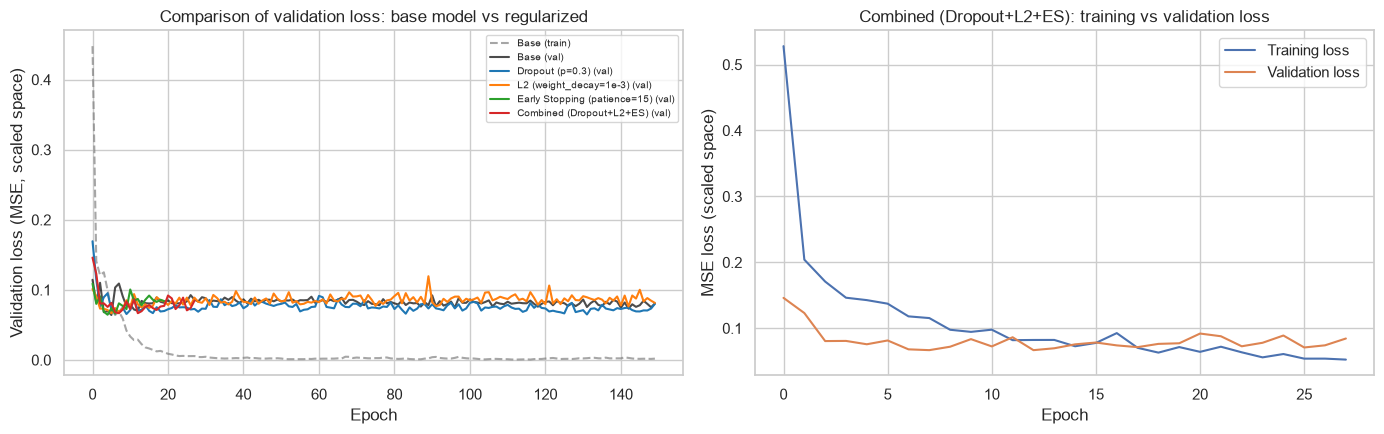

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(history_base['train_loss'], label='Base (train)', color='gray', linestyle='--', alpha=0.7)
axes[0].plot(history_base['val_loss'], label='Base (val)', color='black', alpha=0.7)
colors = plt.cm.tab10.colors
for i, (name, history) in enumerate(reg_histories.items()):
    axes[0].plot(history['val_loss'], label=f'{name} (val)', color=colors[i % 10])
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation loss (MSE, scaled space)')
axes[0].set_title('Comparison of validation loss: base model vs regularized')
axes[0].legend(fontsize=7)

combo_name = 'Combined (Dropout+L2+ES)'
axes[1].plot(reg_histories[combo_name]['train_loss'], label='Training loss')
axes[1].plot(reg_histories[combo_name]['val_loss'], label='Validation loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE loss (scaled space)')
axes[1].set_title(f'{combo_name}: training vs validation loss')
axes[1].legend()

plt.tight_layout()
plt.show()

## 14–15. Comparative table of the MLP configurations

In [35]:
best_arch_name = architecture_results_df.loc[
    architecture_results_df['architecture'] != 'Base (2 layers, 128-64)', 'R2_val'
].astype(float).idxmax()
best_arch_name = architecture_results_df.loc[best_arch_name, 'architecture']
best_arch_model = architecture_models[best_arch_name]

best_reg_name = reg_results_df['R2_val'].astype(float).idxmax()
best_reg_name = reg_results_df.loc[best_reg_name, 'configuration']
best_reg_model = reg_models[best_reg_name]

print(f"Best alternative architecture (by R2_val): {best_arch_name}")
print(f"Best configuration with regularization (by R2_val): {best_reg_name}")

Best alternative architecture (by R2_val): Deeper (3 layers, 128-64-32)
Best configuration with regularization (by R2_val): Early Stopping (patience=15)


In [38]:
def full_eval_row(model, name, n_epochs_trained, train_time, best_val_loss):
    val_m = evaluate_model(model, X_val_t, y_val_scaled, y_scaler)
    return {
        'Configuration': name,
        'Number of parameters': count_parameters(model),
        'Epochs trained': n_epochs_trained,
        'Best val_loss (MSE, scaled)': round(best_val_loss, 4),
        'MAE_val': round(val_m['MAE'], 1), 'RMSE_val': round(val_m['RMSE'], 1), 'R2_val': round(val_m['R2'], 4),
        'Training time, s': round(train_time, 2),
    }

final_comparison = pd.DataFrame([
    full_eval_row(model_base, 'Base MLP (128-64, without regularization)',
                   info_base['n_epochs_trained'], info_base['train_time'], info_base['best_val_loss']),
    full_eval_row(best_arch_model, f'MLP with modified architecture ({best_arch_name})',
                   N_EPOCHS_BASE, architecture_results_df.set_index('architecture').loc[best_arch_name, 'train_time_s'],
                   architecture_results_df.set_index('architecture').loc[best_arch_name, 'best_val_loss']),
    full_eval_row(best_reg_model, f'MLP with regularization ({best_reg_name})',
                   reg_infos[best_reg_name]['n_epochs_trained'], reg_infos[best_reg_name]['train_time'],
                   reg_infos[best_reg_name]['best_val_loss']),
]).set_index('Configuration')

final_comparison

,Number of parameters,Epochs trained,"Best val_loss (MSE, scaled)",MAE_val,RMSE_val,R2_val,"Training time, s"
Configuration,,,,,,,
"Base MLP (128-64, without regularization)",47361,150,0.0642,14273.1,21113.3,0.9279,9.92
"MLP with modified architecture (Deeper (3 layers, 128-64-32))",49409,150,0.0686,15040.9,21825.3,0.9230,9.54
MLP with regularization (Early Stopping (patience=15)),47361,20,0.0646,14265.4,21176.1,0.9275,1.10


## 16. Selecting the most suitable MLP configuration

In [39]:
final_models = {
    'Base MLP': model_base,
    f'Architecture: {best_arch_name}': best_arch_model,
    f'Regularization: {best_reg_name}': best_reg_model,
}

best_config_name = final_comparison['R2_val'].idxmax()
print(f"By the criterion of the highest R2_val, selected: {best_config_name}")

name_to_model = {
    'Base MLP (128-64, without regularization)': model_base,
    f'MLP with modified architecture ({best_arch_name})': best_arch_model,
    f'MLP with regularization ({best_reg_name})': best_reg_model,
}
final_model = name_to_model[best_config_name]

By the criterion of the highest R2_val, selected: Base MLP (128-64, without regularization)


## 17. Final evaluation of the selected configuration

In [ ]:
X_trainval_raw = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

prep_final = build_preprocessor(X_trainval_raw)
X_trainval_final = apply_preprocessor(X_trainval_raw, prep_final).reset_index(drop=True)
X_test_final_2 = apply_preprocessor(X_test, prep_final).reset_index(drop=True)

y_scaler_final = StandardScaler()
y_trainval_scaled = y_scaler_final.fit_transform(y_trainval.values.reshape(-1, 1)).ravel()
y_test_scaled_2 = y_scaler_final.transform(y_test.values.reshape(-1, 1)).ravel()

X_trainval_t2, y_trainval_t2 = to_tensor(X_trainval_final, y_trainval_scaled)
X_test_t2, y_test_t2 = to_tensor(X_test_final_2, y_test_scaled_2)

trainval_dataset = TensorDataset(X_trainval_t2, y_trainval_t2)
trainval_loader = DataLoader(trainval_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(RANDOM_STATE))

config_lookup = {
    'Base MLP (128-64, without regularization)': dict(hidden_sizes=(128, 64), dropout_p=0.0, weight_decay=0.0,
                                                      early_stopping_patience=None, n_epochs=N_EPOCHS_BASE),
    f'MLP with modified architecture ({best_arch_name})': dict(
        hidden_sizes=architectures[best_arch_name]['hidden_sizes'], dropout_p=0.0, weight_decay=0.0,
        early_stopping_patience=None, n_epochs=N_EPOCHS_BASE),
    f'MLP with regularization ({best_reg_name})': dict(
        hidden_sizes=(128, 64), dropout_p=regularization_configs[best_reg_name]['dropout_p'],
        weight_decay=regularization_configs[best_reg_name]['weight_decay'],
        early_stopping_patience=regularization_configs[best_reg_name]['early_stopping_patience'],
        n_epochs=N_EPOCHS_BASE),
}
chosen_cfg = config_lookup[best_config_name]


n_features_final = X_trainval_final.shape[1]
print(f"Input layer dimensionality for retraining on train+val: {n_features_final} ")


torch.manual_seed(RANDOM_STATE)
final_model_retrained = MLPRegressor(input_dim=n_features_final, hidden_sizes=chosen_cfg['hidden_sizes'],
                                      dropout_p=chosen_cfg['dropout_p'])

final_model_retrained, history_final, info_final = train_model(
    final_model_retrained, trainval_loader, X_test_t2, y_test_t2,
    n_epochs=chosen_cfg['n_epochs'], learning_rate=LEARNING_RATE,
    weight_decay=chosen_cfg['weight_decay'],
    early_stopping_patience=chosen_cfg['early_stopping_patience'], verbose=False
)

print(f"Final model ({best_config_name}) retrained on train+val "
      f"({X_trainval_final.shape[0]} objects), {info_final['n_epochs_trained']} epochs.")

Input layer dimensionality for retraining on train+val: 312 (was 304 features when training on train only)
Final model (Base MLP (128-64, without regularization)) retrained on train+val (1168 objects), 150 epochs.


In [41]:
final_test_metrics = evaluate_model(final_model_retrained, X_test_t2, y_test_scaled_2, y_scaler_final)

print("Final metrics on the test sample:")
pd.Series(final_test_metrics).to_frame('test')

Final metrics on the test sample:


,test
MAE,1.463982e+04
MSE,7.760540e+08
RMSE,2.785775e+04
R2,8.266471e-01


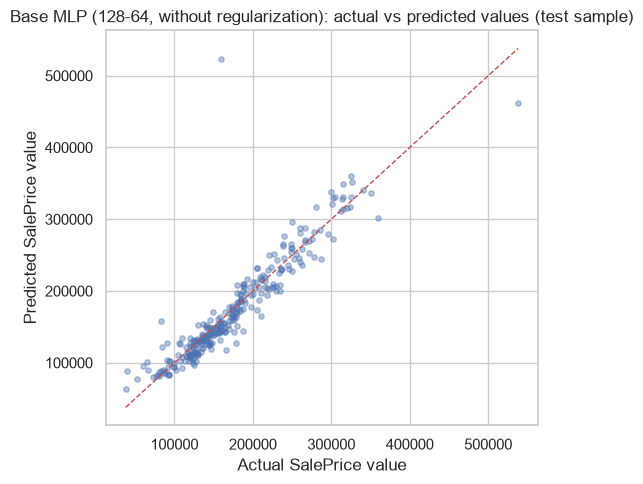

In [42]:
y_test_pred = y_scaler_final.inverse_transform(
    predict_np(final_model_retrained, X_test_t2).reshape(-1, 1)
).ravel()

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test.values, y_test_pred, alpha=0.4, s=15)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1)
plt.xlabel('Actual SalePrice value')
plt.ylabel('Predicted SalePrice value')
plt.title(f'{best_config_name}: actual vs predicted values (test sample)')
plt.tight_layout()
plt.show()

## 18. Final justification of the selected MLP configuration

In [44]:
print("Comparison of the three studied configurations on validation:")
display(final_comparison)

print(f"\nSelected configuration: {best_config_name}")
display(pd.Series(final_test_metrics).to_frame('test'))

Comparison of the three studied configurations on validation:


,Number of parameters,Epochs trained,"Best val_loss (MSE, scaled)",MAE_val,RMSE_val,R2_val,"Training time, s"
Configuration,,,,,,,
"Base MLP (128-64, without regularization)",47361,150,0.0642,14273.1,21113.3,0.9279,9.92
"MLP with modified architecture (Deeper (3 layers, 128-64-32))",49409,150,0.0686,15040.9,21825.3,0.9230,9.54
MLP with regularization (Early Stopping (patience=15)),47361,20,0.0646,14265.4,21176.1,0.9275,1.10



Selected configuration: Base MLP (128-64, without regularization)


,test
MAE,1.463982e+04
MSE,7.760540e+08
RMSE,2.785775e+04
R2,8.266471e-01
